In [50]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(dirname(os.getcwd())))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import IsaacCfg as cf
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors, freeze_parameters
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.scaler import RunningStandardScaler
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO, create_memories, reset_memories
from memoryPerceiver.memory_perceiver.processing.vectorize import patchify

from matplotlib import pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
cf.frames=1
cf.num_envs=4
cf.dim_observations=3

In [52]:
device = 'cuda:0'
model = create_agent(cf.agent_type, cf, rank=0)
if isinstance(model, ActorCriticPerceiver):
    memories = create_memories(model.actor, cf.num_envs, device=device)
else:
    memories=None

In [34]:
mask = tr.create_mask(torch.tensor([403, 405], device=device), 405, 4)
mask

tensor([[False,  True,  True,  True],
        [False, False, False,  True]], device='cuda:0')

In [34]:
tt = tr.batch_and_mask_states({'obs': torch.ones(cf.frames, cf.num_envs, cf.dim_observations, device=device),
                'actions_star': torch.ones(cf.frames, cf.num_envs, cf.dim_actions, device=device)}, 
    cf , mask, device)
tt['obs']

IndexError: The shape of the mask [2, 4] at index 0 does not match the shape of the indexed tensor [16384, 1, 3] at index 0

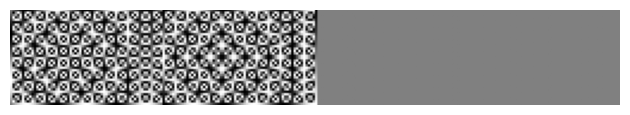

In [41]:
ts.show((1+model.actor.state_embedding.scalar_pos)/2)

In [13]:
model.actor.state_embedding.scalar_pos.shape

torch.Size([1, 256])

In [12]:
model.actor.state_embedding.vector_pos['video'].shape

torch.Size([1, 16, 28, 256])

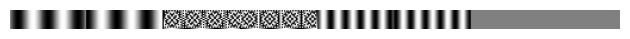

In [45]:
ts.show(model.actor.state_embedding.vector_pos['video'][0, :, 3])

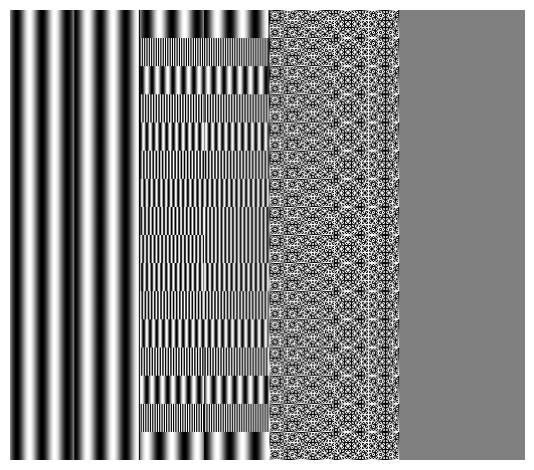

In [49]:
ts.show(rearrange(model.actor.state_embedding.vector_pos['video'][0], 'h w d -> (h w) d'))

In [53]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
model.train()
states = {}
# for i in range(4):
states['obs'] = torch.randn(cf.num_envs, cf.frames, cf.dim_observations, device=device)
states['actions_star'] = torch.ones(cf.num_envs, cf.frames, cf.dim_actions, device=device)
states['video'] = torch.randn(cf.num_envs, cf.frames, cf.height, cf.width, cf.channels, device=device)
out = model(states, memories, torch.zeros(cf.num_envs, cf.dim_actions_ppo, device=device))
out

{'actions': tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]],
        device='cuda:0'),
 'actions_mean': tensor([[-0.0152,  0.2464,  0.0608,  0.1311,  0.1082, -0.0570, -0.0009, -0.0854,
           0.1024,  0.0258,  0.0755, -0.0699,  0.0288, -0.0015, -0.0126, -0.2204,
           0.0160,  0.0917, -0.0006,  0.0329,  0.0395],
         [-0.0249,  0.2465,  0.0466,  0.1249,  0.0993, -0.0673,  0.0050, -0.0744,
           0.1056,  0.0114,  0.0756, -0.0768,  0.0264,  0.0010, -0.0073, -0.2253,
           0.0219,  0.0930, -0.0109,  0.0475,  0.0268],
         [-0.0212,  0.2429,  0.0495,  0.1294,  0.1070, -0.0585, -0.0052, -0.0858,
           0.1095,  0.0175,  0.0898, -0.0680

In [12]:
loss_all = []

In [37]:
out["actions_mean"].mean(dim=-1)

tensor([6.8449e-04, 2.3813e-04, 5.8186e-04,  ..., 5.5560e-05, 8.4302e-04,
        2.3878e-04], device='cuda:0', grad_fn=<MeanBackward1>)

In [13]:
for i in range(30000):
    states['obs'] = 0.5*torch.ones(cf.num_envs, 1, cf.dim_observations, device=device)
    maskk = torch.bernoulli(torch.full((cf.num_envs,), 0.5, device=device)).long()
    states['obs'][maskk.bool()] *= -1
    y_target =  states['obs'].detach().mean(dim=[1,2])

    # with torch.no_grad():
    #     oo = model(states, memories)
    #     taken_actions = oo["actions"].detach()
    # out = model(states, memories, taken_actions)
    out = model(states, memories)

    # mse = F.mse_loss(taken_actions.mean(dim=-1), y_target)
    # loss = (out["logprobs"] * mse).mean()
    loss = F.mse_loss(out["values"],y_target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # with torch.no_grad():  # No tracking of gradients during the update
    #     for param in model.parameters():
    #         if param.grad is not None:
    #             param -= 1e-4 * param.grad
    loss_all.append(loss.mean().item())
    if i % 100 == 0:
        print('loss',loss.item())
        # print('loss',mse.mean().item())
        # print(states['obs'][0:10].mean(dim=[1,2]))
        # print(out['actions_mean'].mean(dim=-1)[0:10])
        print(y_target[:10])
        print(out["values"][:10])
    

loss 0.24998930096626282
tensor([-0.5000,  0.5000, -0.5000, -0.5000,  0.5000,  0.5000,  0.5000, -0.5000,
         0.5000,  0.5000], device='cuda:0')
tensor([-0.0007, -0.0007, -0.0007, -0.0007, -0.0007, -0.0007, -0.0007, -0.0007,
        -0.0007, -0.0007], device='cuda:0', grad_fn=<SliceBackward0>)
loss 0.00029905480914749205
tensor([ 0.5000, -0.5000, -0.5000, -0.5000,  0.5000, -0.5000,  0.5000, -0.5000,
         0.5000,  0.5000], device='cuda:0')
tensor([ 0.5120, -0.4787, -0.4787, -0.4787,  0.5120, -0.4787,  0.5120, -0.4787,
         0.5120,  0.5120], device='cuda:0', grad_fn=<SliceBackward0>)
loss 2.454318703826175e-08
tensor([-0.5000,  0.5000, -0.5000, -0.5000,  0.5000, -0.5000, -0.5000, -0.5000,
         0.5000, -0.5000], device='cuda:0')
tensor([-0.5001,  0.4998, -0.5001, -0.5001,  0.4998, -0.5001, -0.5001, -0.5001,
         0.4998, -0.5001], device='cuda:0', grad_fn=<SliceBackward0>)
loss 6.988886136483075e-10
tensor([-0.5000,  0.5000, -0.5000,  0.5000,  0.5000,  0.5000, -0.5000, 

KeyboardInterrupt: 

In [25]:
print(states['obs'][0:7].mean(dim=[1,2]), out["actions_mean"][0:7].mean(dim=-1))

tensor([-0.5000, -0.5000, -0.5000, -0.5000, -0.5000, -0.5000,  0.5000],
       device='cuda:0') tensor([-0.0476, -0.0476, -0.0476, -0.0476, -0.0476, -0.0476, -0.0476],
       device='cuda:0', grad_fn=<MeanBackward1>)


In [64]:
oo["actions"][0:7].mean(dim=-1)

tensor([-0.4309,  0.3642, -0.8429,  0.2274, -0.3366, -0.5392, -0.1119],
       device='cuda:0')

In [59]:
out["actions_mean"][0:7, :7]

tensor([[ -2.1496, -20.7240,   9.5991,   8.2367,  -8.1675,   4.3280,  -6.6198],
        [ -2.1496, -20.7240,   9.5991,   8.2367,  -8.1675,   4.3280,  -6.6198],
        [ -2.1496, -20.7240,   9.5991,   8.2367,  -8.1675,   4.3280,  -6.6198],
        [ -5.6363, -37.0039,  13.5638,  15.5180, -14.4418,  10.3361, -12.9108],
        [ -5.6363, -37.0039,  13.5638,  15.5180, -14.4418,  10.3361, -12.9108],
        [ -2.1496, -20.7240,   9.5991,   8.2367,  -8.1675,   4.3280,  -6.6198],
        [ -2.1496, -20.7240,   9.5991,   8.2367,  -8.1675,   4.3280,  -6.6198]],
       device='cuda:0', grad_fn=<SliceBackward0>)

In [74]:
out["actions_std"][0:7]

tensor([0.8606, 0.8956, 0.9689, 1.0078, 0.8677, 1.0244, 1.0253],
       device='cuda:0', grad_fn=<SliceBackward0>)

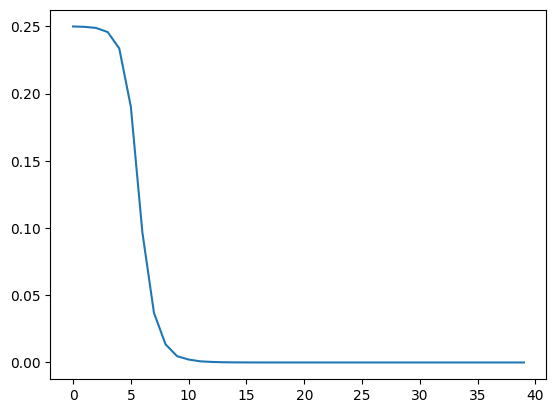

In [14]:
n = 40
l = len(loss_all) // n
plt.plot([np.mean(loss_all[i * l: (i + 1) * l]) for i in range(0,n)])

In [12]:
print(y_target[:5])

tensor([-1.5000, -2.5000, -1.5000, -2.5000, -1.5000], device='cuda:0')


In [35]:
print(values[:20])

tensor([2.6062, 1.7422, 1.5893, 1.6826, 1.4687, 1.5767, 1.6690, 2.6060, 1.6801,
        2.6368, 1.9303, 1.5252, 1.6414, 1.5201, 2.6483, 1.5580, 1.4705, 1.5879,
        2.3985, 1.6067], device='cuda:0', grad_fn=<SliceBackward0>)
